**TAREA 2: REGRESIÓN**
-

A lo largo de este notebook se desarrolla la tarea de regresión del proyecto. El objetivo es predecir la variable nota_media_2sem, que representa la calificación media obtenida por el estudiante en el segundo semestre.

Para desarrollar esta tarea correctamente, se excluyen como predictores todas las variables del segundo semestre cuya información sea contemporánea o prácticamente equivalente a la nota que se desea predecir. De esta manera, se evita la fuga de información (data leakage). Esta exclusión se justifica en detalle más adelante.

**1. Carga de datos**

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
import warnings
warnings.filterwarnings("ignore")

from data_loading import cargar_dataset, obtener_features_regresion
from preprocessing import separar_tipos, construir_preprocesador, obtener_nombres_features
from regression import construir_pipelines_regresion, construir_baseline_regresion, evaluar_regresion
from utils import extraer_importancias

df = cargar_dataset("../rendimiento_estudiantes.csv")
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


Cargo el dataset y las librerías necesarias.

**2. Selección de variables y justificación de exclusiones por leakage**

No debo utilizar como predictores o features aquellas variables del segundo semestre cuya nformación sea contemporánea o prácticamente equivalente a la nota que se desea predecir. Por lo tanto, excluyo todas las variables del bloque de rendimiento del segundo semestre. De esta manera, mi predicción será realista. En concreto, estas son las variables que no usaré para construir mi modelo:

- asignaturas_2sem_convalidadas: información del mismo periodo que el target.
- asignaturas_2sem_matriculadas: información del mismo periodo que el target.
- asignaturas_2sem_evaluadas: información del mismo periodo que el target.
- asignaturas_2sem_aprobadas: prácticamente equivalente al target (las asignaturas aprobadas determinan en gran parte la nota media).
- asignaturas_2sem_sin_evaluacion: información del mismo periodo que el target.

También se excluye la propia variable objetivo de clasificación, ya que no es un predictor sino un resultado final.

Las variables que sí se usan como predictores son las restantes: variables demográficas/personales, de acceso y contexto previo, socioeconómicas/administrativas, macroeconómicas y de rendimiento del primer semestre. El objetivo es estudiar si es posible anticipar el rendimiento del segundo semestre a partir de información previa del estudiante.

In [2]:
#obtengo las features de regresión desde src
features_sin_1sem, features_con_1sem, excluidas_leakage = obtener_features_regresion()

target = "nota_media_2sem"

print(f"\nVariables sin 1er semestre: {len(features_sin_1sem)}"
	  f"\nVariables con 1er semestre: {len(features_con_1sem)}"
	  f"\nVariables excluidas por leakage: {len(excluidas_leakage)}"
	  f"\nExcluidas: {excluidas_leakage}")


Variables sin 1er semestre: 24
Variables con 1er semestre: 30
Variables excluidas por leakage: 5
Excluidas: ['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'asignaturas_2sem_sin_evaluacion']


Compruebo que las variables seleccionadas existen en el dataset.

In [3]:
for col in features_con_1sem:
    if col not in df.columns:
        print(f"ERROR: {col} no esta en el dataset")

print("Todas las variables existen en el dataset.")

Todas las variables existen en el dataset.


**3. Identificación de variables numéricas y categóricas**

In [4]:
#identifico numéricas y categóricas usando la función de src
categoricas, numericas = separar_tipos(df, features_con_1sem)

print(f"Categóricas ({len(categoricas)}): {categoricas}"
	  f"\nNuméricas ({len(numericas)}): {numericas}")

Categoricas (17): ['estado_civil', 'nacionalidad', 'desplazado', 'necesidades_educativas_especiales', 'genero', 'internacional', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'deudor', 'matricula_al_dia', 'becado']
Numericas (13): ['edad_al_matricularse', 'orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'tasa_desempleo', 'tasa_inflacion', 'pib', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion']


**4. Separación train/test**

Separo los datos en train y test una sola vez de manera aleatoria con sklearn. Por otra parte, el conjunto de observaciones de test solo se usará al final para la evaluación definitiva.

Fijo una semilla (random_state=42) para que los resultados sean reproducibles. 

In [5]:
X = df[features_con_1sem]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]} observaciones"
	  f"\nTest: {X_test.shape[0]} observaciones")

print("\nEstadisticas del target en train:\n",y_train.describe().round(2))

Train: 3539 observaciones
Test: 885 observaciones

Estadisticas del target en train:
 count    3539.00
mean       10.23
std         5.21
min         0.00
25%        10.80
50%        12.20
75%        13.33
max        18.57
Name: nota_media_2sem, dtype: float64


**5. Pipeline de preprocesado**

Construyo un pipeline que aplique el preprocesado necesario y de esta manera, evitar el data leakage mediante fugas de información entre train y test (data leakage). 

Las variables numércias las estandarizo con StandarScaler mientras que las variables categóricas las codifico de manera binaria a One Hot Encoding.

In [6]:
#construyo el preprocesador usando la función de src
preprocesador = construir_preprocesador(numericas, categoricas)

print(f"Variables numéricas en pipeline: {len(numericas)}"
	  f"\nVariables categóricas en pipeline: {len(categoricas)}")

Variables numericas en pipeline: 13
Variables categoricas en pipeline: 17


**6. Baseline: predicción con la media**

El baseline más simple en regresión es predecir siempre la media del target. Si mis modelos no mejoran esto, no aportan nada.

In [7]:
#baseline usando la función de src
baseline = construir_baseline_regresion()
baseline.fit(X_train, y_train)
y_pred_bl = baseline.predict(X_test)

metricas_bl = evaluar_regresion(y_test, y_pred_bl)

print("-"*8, "Baseline (predicción con la media)", "-"*8)
print(f"RMSE: {metricas_bl['rmse']:.3f}"
	  f"\nMAE:  {metricas_bl['mae']:.3f}"
	  f"\nR2:   {metricas_bl['r2']:.3f}")

-------- Baseline (prediccion con la media) --------
RMSE: 5.203
MAE:  4.022
R2:   -0.000


El baseline da un R² prácticamente 0: predecir la media no explica nada. El RMSE de 5.203 es el suelo contra el que comparar.

**7. Modelo 1: Ridge Regression**

El primer modelo es una regresión Ridge, que es una regresión lineal con regularización L2. La regularización reduce la varianza del modelo penalizando coeficientes grandes, lo cual es útil cuando hay muchas variables (sobre todo tras el one-hot encoding). De esta manera evito que mi modelo tienda al overfitting.

Por otr parte, uso validación cruzada con 5 folds para estimar el rendimiento sin tocar el test.

In [8]:
#construyo los pipelines desde src
pipelines = construir_pipelines_regresion(preprocesador)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

pipe_ridge = pipelines["Ridge"]
scores_ridge_rmse = cross_val_score(pipe_ridge, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
scores_ridge_r2 = cross_val_score(pipe_ridge, X_train, y_train, cv=cv, scoring="r2")

print("-"*8, "RMSE y Ridge (CV)", "-"*8)
print(f"RMSE medio: {-scores_ridge_rmse.mean():.3f} con error de +- {scores_ridge_rmse.std():.3f}"
	  f"\nR2 medio:   {scores_ridge_r2.mean():.3f} con error de +- {scores_ridge_r2.std():.3f}")

-------- RMSE y Ridge (CV) --------
RMSE medio: 2.649 con error de +- 0.063
R2 medio:   0.739 con error de +- 0.027


**8. Modelo 2: Elastic Net**

El segundo modelo es Elastic Net, que combina regularización L1 (Lasso) y L2 (Ridge). La parte L1 puede llevar algunos coeficientes a exactamente cero, lo que equivale a una selección automática de variables.

In [9]:
pipe_enet = pipelines["Elastic Net"]
scores_enet_rmse = cross_val_score(pipe_enet, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
scores_enet_r2 = cross_val_score(pipe_enet, X_train, y_train, cv=cv, scoring="r2")

print("-"*8, "RMSE y Elastic Net (CV)", "-"*8)
print(f"RMSE medio: {-scores_enet_rmse.mean():.3f} con error de +- {scores_enet_rmse.std():.3f}"
	  f"\nR2 medio:   {scores_enet_r2.mean():.3f} con error de +- {scores_enet_r2.std():.3f}")

-------- RMSE y Elastic Net (CV) --------
RMSE medio: 2.659 con error de +- 0.087
R2 medio:   0.737 con error de +- 0.028


**9. Modelo 3: Random Forest**

El tercer modelo es un Random Forest, que es un ensemble no lineal de árboles de decisión. Este modelo permmite mayor complejidad al corregir la varianza de los árboles de decisión y la correlación de Bagging.

In [10]:
pipe_rf = pipelines["Random Forest"]
scores_rf_rmse = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
scores_rf_r2 = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring="r2")

print("-"*8, "Random Forest (CV)", "-"*8)
print(f"RMSE medio: {-scores_rf_rmse.mean():.3f} con error de +- {scores_rf_rmse.std():.3f}"
	  f"\nR2 medio:   {scores_rf_r2.mean():.3f} con error de +- {scores_rf_r2.std():.3f}")

-------- Random Forest (CV) --------
RMSE medio: 2.471 con error de +- 0.114
R2 medio:   0.772 con error de +- 0.033


**10. Modelo 4: Gradient Boosting**

El cuarto modelo es un Gradient Boosting. Al igual que en clasificación, construye árboles de forma secuencial corrigiendo los errores del anterior.

In [11]:
pipe_gb = pipelines["Gradient Boosting"]
scores_gb_rmse = cross_val_score(pipe_gb, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
scores_gb_r2 = cross_val_score(pipe_gb, X_train, y_train, cv=cv, scoring="r2")

print("-"*8, "Gradient Boosting (CV)", "-"*8)
print(f"RMSE medio: {-scores_gb_rmse.mean():.3f} con error de +- {scores_gb_rmse.std():.3f}"
	  f"\nR2 medio:   {scores_gb_r2.mean():.3f} con error de +- {scores_gb_r2.std():.3f}")

-------- Gradient Boosting (CV) --------
RMSE medio: 2.514 con error de +- 0.094
R2 medio:   0.765 con error de +- 0.028


**11. Comparación de modelos en validación cruzada**

Ahora comparo las métricas que reflejan el rendimiento de cada modelo estudiado. 

In [12]:
comparacion = pd.DataFrame({
    "Modelo": ["Ridge", "Elastic Net", "Random Forest", "Gradient Boosting"],
    "RMSE medio": [-scores_ridge_rmse.mean(), -scores_enet_rmse.mean(), 
                   -scores_rf_rmse.mean(), -scores_gb_rmse.mean()],
    "R2 medio": [scores_ridge_r2.mean(), scores_enet_r2.mean(),
                 scores_rf_r2.mean(), scores_gb_r2.mean()]
})

comparacion = comparacion.sort_values("RMSE medio")
comparacion.round(3)

,Modelo,RMSE medio,R2 medio
2,Random Forest,2.471,0.772
3,Gradient Boosting,2.514,0.765
0,Ridge,2.649,0.739
1,Elastic Net,2.659,0.737


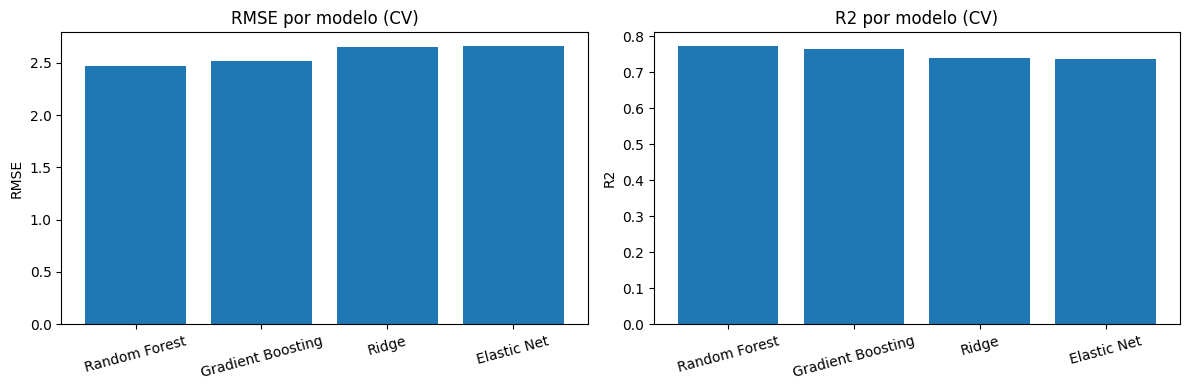

In [13]:
#gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(comparacion["Modelo"], comparacion["RMSE medio"])
axes[0].set_ylabel("RMSE")
axes[0].set_title("RMSE por modelo (CV)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(comparacion["Modelo"], comparacion["R2 medio"])
axes[1].set_ylabel("R2")
axes[1].set_title("R2 por modelo (CV)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**12. Evaluación final en test con el mejor modelo**

Selecciono el modelo con menor RMSE en validación cruzada. Observando los gráficos anteriores (del punto 11), puedo ver que RF tiene el menor RMSE y el R2 más alto. Esto significa que este será el modelo elegido. De todas formas, lo compruebo con el código. 

Una vez seleccionado el modelo, lo entreno con todo el train y evalúo en test por primera y única vez.

In [14]:
#selecciono el mejor modelo según RMSE en CV
resultados_cv = {
    "Ridge": (pipe_ridge, -scores_ridge_rmse.mean()),
    "Elastic Net": (pipe_enet, -scores_enet_rmse.mean()),
    "Random Forest": (pipe_rf, -scores_rf_rmse.mean()),
    "Gradient Boosting": (pipe_gb, -scores_gb_rmse.mean())
}

nombre_mejor = min(resultados_cv, key=lambda k: resultados_cv[k][1])
mejor_pipe = resultados_cv[nombre_mejor][0]

print(f"Mejor modelo según CV: {nombre_mejor}")

#entreno con todo el train
mejor_pipe.fit(X_train, y_train)

#predicciones en test
y_pred = mejor_pipe.predict(X_test)

Mejor modelo segun CV: Random Forest


Efectivamente, el modelo estudiado con mejor rendimiento es RF. Ahora lo voy a entrenar para evaluarlo en test.

In [15]:
#métricas finales en test usando la función de src
metricas_test = evaluar_regresion(y_test, y_pred)

print(f"- Evaluación final en test: {nombre_mejor} ")
print(f"RMSE: {metricas_test['rmse']:.3f}"
	  f"\nMAE:  {metricas_test['mae']:.3f}"
	  f"\nR2:   {metricas_test['r2']:.3f}")

print(f"\nPara referencia, el RMSE del baseline (media) era: {metricas_bl['rmse']:.3f}")

- Evaluacion final en test: Random Forest 
RMSE: 2.728
MAE:  1.404
R2:   0.725

Para referencia, el RMSE del baseline (media) era: 5.203


**13. Gráfico de predicciones vs valores reales**

Represento las predicciones frente a los valores reales. Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal.

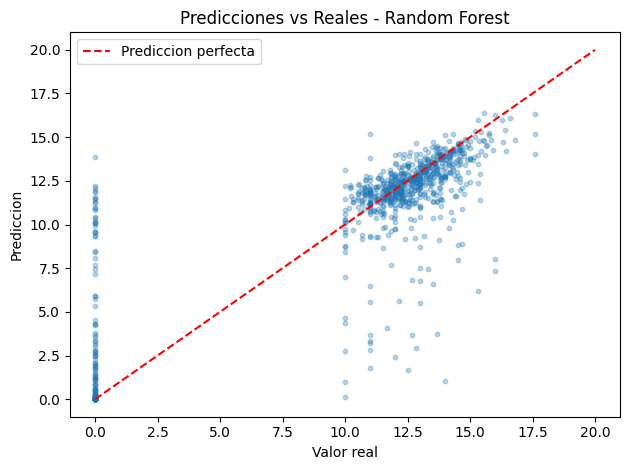

In [16]:
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([0, 20], [0, 20], color="red", linestyle="--", label="Predicción perfecta")
plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title(f"Predicciones vs Reales - {nombre_mejor}")
plt.legend()
plt.tight_layout()
plt.show()

Se puede observar en el gráfico que claramente la predicción no es perfecta. La distribución de datos respecto a la del valor real encaja con la observada en el EDA. Sin embargo, hay predicciones que son erróneas.

Me llama la atención la cantidad de notas 0.0 que se predicen con otro valor, llegando incluso a superar los 12.5. Creo que esto se debe a que el valor de la nota 0 no es por rendimiento académico, sino por abandono. Debido a eso, el modelo tiende a sobreestimar la nota de las observaciones pertenecientes a esta categoría.

**14. Análisis de residuos**

Estudio los residuos (diferencia entre valor real y predicción) para comprobar si el modelo tiene sesgos sistemáticos en algún rango de notas.

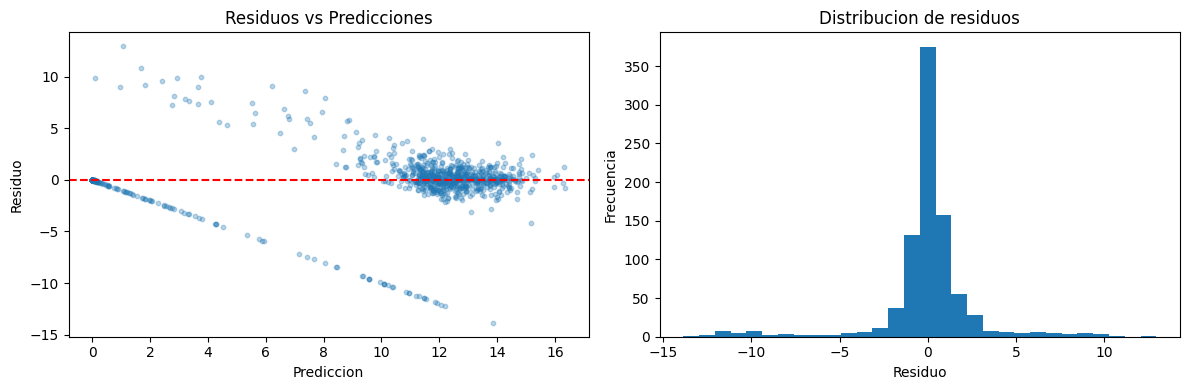

In [17]:
residuos = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#residuos vs predicciones
axes[0].scatter(y_pred, residuos, alpha=0.3, s=10)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Residuo")
axes[0].set_title("Residuos vs Predicciones")

#histograma de residuos
axes[1].hist(residuos, bins=30)
axes[1].set_xlabel("Residuo")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribución de residuos")

plt.tight_layout()
plt.show()

A pesar de que el RF ha sido seleccionado como el mejor modelo en cuanto a rendimiento, observo 2 tendencias que han de ser mencionadas. 

Lo esperado sería obtener los errores centrados en 0 y con una forma algo simétrica. En gran parte, nuestro modelo cumple esto. Sin embargo, el análisis de residuos muestra que nuestro modelo no captura la relación completamente. Concretamente, el modelo no captura correctamente en los extremos. Esto seguramente sea debido a sesgos sistemáticos como el error ya mencionado en cuanto a la influencia de la categoría en la nota. Si nuestro estudiante abandona, independientemente de su rendimiento académico, su nota será 0. 

**15. Comparación de conjuntos de variables: sin vs con primer semestre**

Quiero estudiar cuánto aporta el rendimiento del primer semestre a la predicción. Para ello, voy a comparar el mejor modelo lineal y el mejor no lineal usando las dos versiones de variables

Si la diferencia es grande, significa que el desempeño temprano del estudiante es un predictor clave del rendimiento futuro.

In [18]:
#preprocesador para la versión sin 1er semestre usando src
cat_sin, num_sin = separar_tipos(df, features_sin_1sem)
preprocesador_sin = construir_preprocesador(num_sin, cat_sin)

X_train_sin = X_train[features_sin_1sem]

#pipelines sin 1er semestre desde src
pipelines_sin = construir_pipelines_regresion(preprocesador_sin)

scores_ridge_sin_r2 = cross_val_score(pipelines_sin["Ridge"], X_train_sin, y_train, cv=cv, scoring="r2")
scores_rf_sin_r2 = cross_val_score(pipelines_sin["Random Forest"], X_train_sin, y_train, cv=cv, scoring="r2")

print("-"*8, "SIN 1er semestre", "-"*8)
print(f"Ridge R2: {scores_ridge_sin_r2.mean():.3f}"
	  f"\nRF R2: {scores_rf_sin_r2.mean():.3f}")

print("-"*8, "CON 1er semestre", "-"*8)
print(f"Ridge R2: {scores_ridge_r2.mean():.3f}")
print(f"\nRF R2: {scores_rf_r2.mean():.3f}")

-------- SIN 1er semestre --------
Ridge R2: 0.288
RF R2: 0.319
-------- CON 1er semestre --------
Ridge R2: 0.739

RF R2: 0.772


Como se puede observar, sí se puede anticipar el rendimiento del segundo semestre con información previa. La diferencia se ve claramente reflajada en las métricas.

**16. Importancia de variables**

Finalmente, extraigo la importancia de las variables del mejor modelo para entender qué factores están más asociados con el rendimiento del segundo semestre.

In [19]:
#importancia de variables usando funciones de src
mejor_pipe.fit(X_train, y_train)

nombres_features = obtener_nombres_features(mejor_pipe.named_steps["preprocesador"], numericas, categoricas)
modelo_interno = mejor_pipe.named_steps["modelo"]
importancias, tipo_importancia = extraer_importancias(modelo_interno)

imp_df = pd.DataFrame({
    "variable": nombres_features,
    "importancia": importancias
}).sort_values("importancia", ascending=False)

print("Top 15 variables más importantes:")
imp_df.head(15)

Top 15 variables mas importantes:


,variable,importancia
10,asignaturas_1sem_aprobadas,0.699833
11,nota_media_1sem,0.074685
3,nota_admision,0.021019
9,asignaturas_1sem_evaluadas,0.021018
0,edad_al_matricularse,0.012661
2,nota_cualificacion_previa,0.012039
4,tasa_desempleo,0.008792
5,tasa_inflacion,0.007658
6,pib,0.006249
8,asignaturas_1sem_matriculadas,0.005538


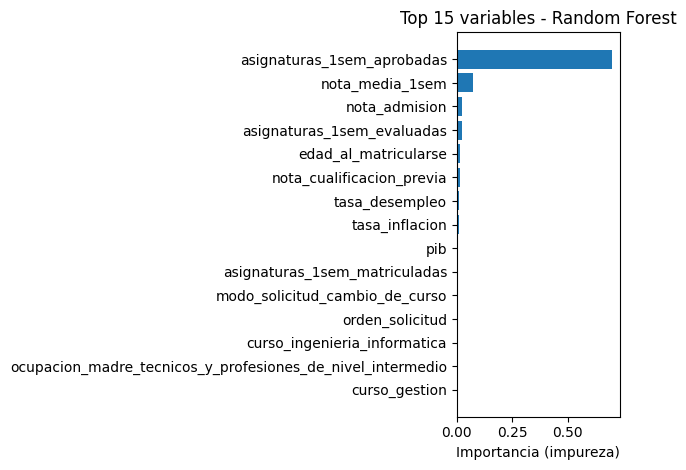

In [20]:
#gráfico
top15 = imp_df.head(15)
plt.barh(top15["variable"], top15["importancia"])
plt.xlabel(tipo_importancia)
plt.title(f"Top 15 variables - {nombre_mejor}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Era de esperar que las variables que reflejan el rendimiento académico del estudiante en el primer semestre influyerán enormemente en la predicción. Como se ha mostrado, no solo es así, sino que también la feature que más aporta a la predicción es la del número de asignaturas aprobadas en el primer semestre. 

**17. Interpretación de resultados de regresión**

A contiuación, se presenta el resumen y las conclusiones de la tarea de regreión.

En primer lugar, para construir un conjunto de datos correcto con el que entrenar y seleccionar el modelo, se excluyeron todas las variables del segundo semestre. Esto se debe a que contienen información contemporánea al target o prácticamente equivalente a él. Por lo tanto, el modelo se construye solo con información previa: perfil del estudiante, contexto socioeconómico, situación administrativa y rendimiento del primer semestre.

El mejor modelo (Random Forest) obtiene un RMSE de 2.728, MAE de 1.404 y R² de 0.725 en test, frente a un RMSE de 5.203 del baseline. Al mejorar el rendimiento frente al baseline, se confirma que es posible anticipar el rendimiento del segundo semestre con la información disponible al final del primero.

La comparación entre modelos lineales y no lineales muestra que Ridge (R²=0.739) y Random Forest (R²=0.772) están relativamente cerca. Los modelos no lineales capturan algo más de variabilidad, pero la relación es en gran parte aditiva.

Sin las variables del primer semestre, el R² cae a 0.29–0.32. Con ellas sube a 0.74–0.77. La ganancia es enorme. Este hecho confirma que el primer semestre es el bloque más informativo para predecir la nota del segundo.

La variable dominante es asignaturas_1sem_aprobadas, seguida de nota_media_1sem y nota_admision. El resto de variables aportan relativamente poco.

El gráfico de residuos muestra una acumulación de errores en la zona de notas reales cercanas a 0, que corresponde a estudiantes que abandonaron. El modelo tiende a sobreestimar la nota de estos estudiantes, lo cual es esperable dado que su nota real es 0 por abandono, no por rendimiento académico.
